<a href="https://colab.research.google.com/github/Shwoouu/AAI2025/blob/2026fall/Agentic_AI_in_Marketing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Existing input data found.


,Advertising Channel,Daily Budget ($),Budget Share (%),Recommendation Rationale
0,Google Search,$102.79,34.26%,Uses a 15% minimum allocation and distributes ...
1,Social Media,$118.38,39.46%,Uses a 15% minimum allocation and distributes ...
2,Display Ads,$78.83,26.28%,Uses a 15% minimum allocation and distributes ...


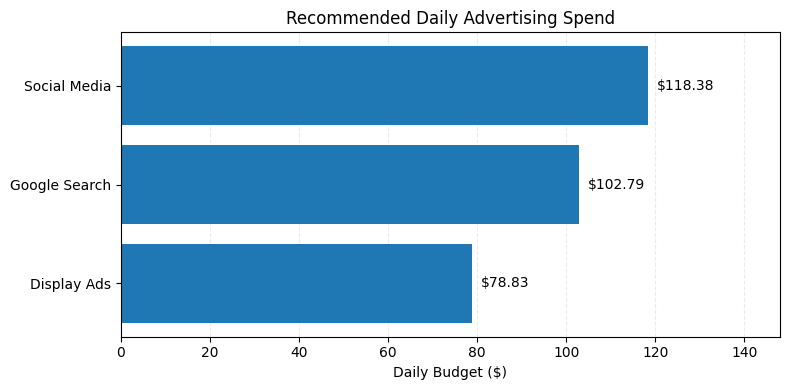

,Performance Metric,Result
0,Days of Data,2
1,Total Advertising Spend,$600.00
2,Total Impressions,"109,800"
3,Total Clicks,"3,388"
4,Total Conversions,217
5,Click-Through Rate (CTR),3.09%
6,Conversion Rate (CVR),6.40%
7,Cost per Acquisition (CPA),$2.76


Files created:
- ad_performance_data.csv
- budget_decisions.csv
- evaluation_metrics.csv


In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

DATA_DIR = Path.cwd()
INPUT_FILE = DATA_DIR / "ad_performance_data.csv"
BUDGET_FILE = DATA_DIR / "budget_decisions.csv"
METRICS_FILE = DATA_DIR / "evaluation_metrics.csv"

DAILY_BUDGET = 300.00
CHANNELS = ["Google Search", "Social Media", "Display Ads"]

if not INPUT_FILE.exists():
    sample = pd.DataFrame([
        {"date":"2026-10-20","channel":"Google Search","spend":200,"impressions":12000,"clicks":900,"conversions":72},
        {"date":"2026-10-20","channel":"Social Media","spend":60,"impressions":18000,"clicks":540,"conversions":27},
        {"date":"2026-10-20","channel":"Display Ads","spend":40,"impressions":25000,"clicks":250,"conversions":8},
        {"date":"2026-10-21","channel":"Google Search","spend":205,"impressions":12500,"clicks":925,"conversions":75},
        {"date":"2026-10-21","channel":"Social Media","spend":55,"impressions":17500,"clicks":525,"conversions":26},
        {"date":"2026-10-21","channel":"Display Ads","spend":40,"impressions":24800,"clicks":248,"conversions":9},
    ])
    sample.to_csv(INPUT_FILE, index=False)
    print("Sample data created.")
else:
    print("Existing input data found.")

data = pd.read_csv(INPUT_FILE)

required = {
    "date", "channel", "spend",
    "impressions", "clicks", "conversions"
}
missing = required - set(data.columns)

if missing:
    raise ValueError(
        f"Input file is missing columns: {', '.join(sorted(missing))}"
    )

data["date"] = pd.to_datetime(data["date"], errors="coerce")

for col in ["spend", "impressions", "clicks", "conversions"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.dropna(
    subset=["date", "channel", "spend",
            "impressions", "clicks", "conversions"]
)
data = data[data["channel"].isin(CHANNELS)].copy()

if data.empty:
    raise ValueError(
        "No usable data found. Check the input file and channel names."
    )

channel_data = (
    data.groupby("channel", as_index=False)
    .agg(
        spend=("spend", "sum"),
        impressions=("impressions", "sum"),
        clicks=("clicks", "sum"),
        conversions=("conversions", "sum")
    )
)

channel_data = pd.DataFrame({"channel": CHANNELS}).merge(
    channel_data, on="channel", how="left"
).fillna(0)

safe_spend = channel_data["spend"].where(
    channel_data["spend"] != 0
)
signals = (
    channel_data["conversions"] / safe_spend
).fillna(0).astype(float)

minimum_share = 0.15
remaining_share = 1 - minimum_share * len(CHANNELS)

if signals.sum() <= 0:
    extra_shares = pd.Series(
        [remaining_share / len(CHANNELS)] * len(CHANNELS)
    )
else:
    extra_shares = signals / signals.sum() * remaining_share

shares = (
    pd.Series([minimum_share] * len(CHANNELS))
    + extra_shares
)

recommended = (shares * DAILY_BUDGET).round(2)

difference = round(DAILY_BUDGET - recommended.sum(), 2)
recommended.iloc[-1] = round(
    recommended.iloc[-1] + difference, 2
)

decision_date = data["date"].max().date().isoformat()
budget_rows = []

for i, row in channel_data.iterrows():
    amount = float(recommended.iloc[i])

    budget_rows.append({
        "decision_date": decision_date,
        "channel": row["channel"],
        "recommended_daily_budget": amount,
        "budget_share_percent": amount / DAILY_BUDGET * 100,
        "rationale": (
            "Uses a 15% minimum allocation and distributes "
            "the remaining budget based on conversions per dollar."
        )
    })

pd.DataFrame(budget_rows).to_csv(BUDGET_FILE, index=False)

total_spend = float(data["spend"].sum())
impressions = int(data["impressions"].sum())
clicks = int(data["clicks"].sum())
conversions = int(data["conversions"].sum())

metrics = pd.DataFrame([{
    "days_of_data": int(data["date"].dt.date.nunique()),
    "total_spend": total_spend,
    "total_impressions": impressions,
    "total_clicks": clicks,
    "total_conversions": conversions,
    "CTR_percent": clicks / impressions * 100 if impressions else 0,
    "CVR_percent": conversions / clicks * 100 if clicks else 0,
    "CPA": total_spend / conversions if conversions else 0
}])

metrics.to_csv(METRICS_FILE, index=False)

budgets = pd.read_csv(BUDGET_FILE)
metrics = pd.read_csv(METRICS_FILE)

budgets["decision_date"] = pd.to_datetime(
    budgets["decision_date"], errors="coerce"
)

latest = budgets[
    budgets["decision_date"] == budgets["decision_date"].max()
].copy()

summary = metrics.iloc[-1]
daily_budget = float(
    latest["recommended_daily_budget"].sum()
)

display(HTML("""
<h1>Ad Optimization Dashboard</h1>
<p>Advertising performance and budget recommendations</p>
"""))

cards = [
    ("Recommended Daily Budget", f"${daily_budget:,.2f}"),
    ("Total Conversions", f'{int(summary["total_conversions"]):,}'),
    ("Click-Through Rate", f'{summary["CTR_percent"]:.2f}%'),
    ("Cost per Acquisition", f'${summary["CPA"]:,.2f}')
]

html = '<div style="display:flex;flex-wrap:wrap;gap:10px;">'

for label, value in cards:
    html += f"""
    <div style="flex:1;min-width:160px;border:1px solid #999;
                padding:12px;border-radius:5px;">
        <div>{label}</div>
        <h2>{value}</h2>
    </div>
    """

html += "</div>"
display(HTML(html))

display(HTML("<h2>1. Recommended Budget Allocation</h2>"))

budget_view = latest[
    ["channel", "recommended_daily_budget",
     "budget_share_percent", "rationale"]
].copy()

budget_view = budget_view.rename(columns={
    "channel": "Advertising Channel",
    "recommended_daily_budget": "Daily Budget ($)",
    "budget_share_percent": "Budget Share (%)",
    "rationale": "Recommendation Rationale"
})

budget_view["Daily Budget ($)"] = budget_view[
    "Daily Budget ($)"
].map(lambda x: f"${x:,.2f}")

budget_view["Budget Share (%)"] = budget_view[
    "Budget Share (%)"
].map(lambda x: f"{x:.2f}%")

display(budget_view)

display(HTML("<h2>2. Budget by Channel</h2>"))

chart = latest.sort_values("recommended_daily_budget")

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(
    chart["channel"],
    chart["recommended_daily_budget"]
)

ax.set_xlabel("Daily Budget ($)")
ax.set_title("Recommended Daily Advertising Spend")
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

for bar, amount in zip(
    bars, chart["recommended_daily_budget"]
):
    ax.text(
        bar.get_width() + 2,
        bar.get_y() + bar.get_height() / 2,
        f"${amount:,.2f}",
        va="center"
    )

ax.set_xlim(
    0,
    max(chart["recommended_daily_budget"].max() * 1.25, 1)
)
plt.tight_layout()
plt.show()

display(HTML("<h2>3. Campaign Performance Summary</h2>"))

performance = pd.DataFrame({
    "Performance Metric": [
        "Days of Data",
        "Total Advertising Spend",
        "Total Impressions",
        "Total Clicks",
        "Total Conversions",
        "Click-Through Rate (CTR)",
        "Conversion Rate (CVR)",
        "Cost per Acquisition (CPA)"
    ],
    "Result": [
        f'{int(summary["days_of_data"]):,}',
        f'${summary["total_spend"]:,.2f}',
        f'{int(summary["total_impressions"]):,}',
        f'{int(summary["total_clicks"]):,}',
        f'{int(summary["total_conversions"]):,}',
        f'{summary["CTR_percent"]:.2f}%',
        f'{summary["CVR_percent"]:.2f}%',
        f'${summary["CPA"]:,.2f}'
    ]
})

display(performance)

passed = (
    abs(daily_budget - DAILY_BUDGET) < 0.02
    and (latest["budget_share_percent"] >= 15 - 0.01).all()
    and (latest["recommended_daily_budget"] >= 0).all()
)

if passed:
    display(HTML(
        "<p><b>Budget Check: PASSED.</b> "
        "The total budget is $300 and each channel meets the "
        "minimum allocation.</p>"
    ))
else:
    display(HTML(
        "<p><b>Budget Check: REVIEW REQUIRED.</b> "
        "Please check the recommendations.</p>"
    ))

display(HTML("""
<p><i>Note: Results use sample data unless you provide your own.
Recommendations do not change live advertising campaigns.</i></p>
"""))

print("Files created:")
print("-", INPUT_FILE.name)
print("-", BUDGET_FILE.name)
print("-", METRICS_FILE.name)
